# Case 2, chapter 7: Train early, score late: when does the model go stale?

*Applies chapter 2 (the error bill in rupees under the chosen threshold) and chapter 3 (staleness: the monitoring rule and the weakest segment) to the bank's calls in time order.*

**Who needs the answer.** The product manager who owns the call list after Monday, and Anand, whose budget assumed this month's bill looks like last month's. A stale model keeps producing confident scores while the bill drifts away from the plan.

**The questions on the way.** What happens to the score, the promise and the bill when the model is trained on the early months and used on the later ones? Which number moves first? What one-sentence rule would have caught it, and when? Inside today's validation slice, which segment does the model rank worst, and can we trust that reading?

**What you will be able to do.** Split by time instead of at random, read a calibration gap month by month, write a monitoring rule with its number, ceiling, window and owner, and measure the weakest segment with its sample size beside it.

**Search terms.** model drift, model monitoring, calibration, temporal split, segment analysis.

## What does case 1 hand us?

The same pipeline and the same chosen model, the regularised logistic. One fact case 1 never used: the dataset's own notes say the rows run in date order from May 2008 to November 2010. The file has a month column and no year, so the year is rebuilt by counting each time the month goes backwards.

In [1]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (8, 3.6), "figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10.5, "axes.titleweight": "bold"})
INK, VIOLET, ROSE, GREEN, MUTED, LILAC = "#1A0F5C", "#5B3FD6", "#D63A6A", "#1F8A5B", "#6B6690", "#CFC9EE"

def check(label, ok):
    """Print PASS or FAIL on its own line; a failed check never stops the notebook."""
    print(("PASS  " if ok else "FAIL  ") + label)

# The Week 5 pipeline: the same file, columns and split every case notebook starts from.
import io, zipfile, pathlib, urllib.request
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

CACHE = pathlib.Path.home() / ".cache" / "c2_datasets"
CACHE.mkdir(parents=True, exist_ok=True)

def load_bank():
    """UCI Bank Marketing, bank-additional-full.csv (CC BY 4.0), cached after the first download."""
    f = CACHE / "bank-additional-full.csv"
    if not f.exists():
        url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"  # verified 28 October 2026
        outer = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url, timeout=60).read()))
        inner = zipfile.ZipFile(io.BytesIO(outer.read("bank-additional.zip")))
        f.write_bytes(inner.read("bank-additional/bank-additional-full.csv"))
    return pd.read_csv(f, sep=";")

PROFILE = ["age", "job", "marital", "education", "default", "housing", "loan"]
HISTORY = ["contact", "month", "day_of_week", "campaign", "previous", "poutcome"]
ECONOMY = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

bank = load_bank()
# Wednesday's honest set: no duration, and pdays split into a flag and the days for those contacted.
bank["never_contacted"] = (bank["pdays"] == 999).astype(int)
bank["days_since"] = bank["pdays"].where(bank["pdays"] != 999, 0)
COLS = PROFILE + HISTORY + ECONOMY + ["never_contacted", "days_since"]
X, y = bank[COLS], (bank["y"] == "yes").astype(int)

# The test slice is sealed first (the envelope on the wall); the rest splits 75/25.
rest, test = train_test_split(bank.index, test_size=0.20, stratify=y, random_state=42)
train, val = train_test_split(rest, test_size=0.25, stratify=y.loc[rest], random_state=42)
NUM = [c for c in COLS if pd.api.types.is_numeric_dtype(bank[c])]
CAT = [c for c in COLS if c not in NUM]

def logistic():
    prep = ColumnTransformer([("num", StandardScaler(), NUM),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])
    return Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=3000))])

print(f"{len(bank):,} rows; train {len(train):,}, validation {len(val):,}, test {len(test):,} (sealed)")
print(f"buyers in validation: {y[val].sum():,} of {len(val):,} ({y[val].mean():.1%})")

MONTHS = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
m_idx = bank["month"].map({m: i for i, m in enumerate(MONTHS)}).to_numpy()
year = 2008 + np.concatenate([[0], np.cumsum(np.diff(m_idx) < 0)])
bank["period"] = [f"{yr}-{mi + 1:02d}" for yr, mi in zip(year, m_idx)]
print("first row", bank["period"].iloc[0], "and last row", bank["period"].iloc[-1])

41,188 rows; train 24,712, validation 8,238, test 8,238 (sealed)
buyers in validation: 928 of 8,238 (11.3%)
first row 2008-05 and last row 2010-11


In [2]:
check("the rebuilt calendar starts in May 2008 and ends in November 2010",
      bank["period"].iloc[0] == "2008-05" and bank["period"].iloc[-1] == "2010-11")
check("the calendar never runs backwards", (pd.Series(bank["period"]).sort_values(kind="stable").values == bank["period"].values).all())

PASS  the rebuilt calendar starts in May 2008 and ends in November 2010
PASS  the calendar never runs backwards


## The options: how do we test what next year looks like?

Two ways to hold out rows: at random, as Monday to Thursday did, which mixes 2008 and 2010 customers into both sides; or by time, training on the earlier 70 percent of rows and scoring the later 30, which is what deployment does. Only the second asks the committee's question.

**Predict before you run.** Trained on May 2008 to April 2009 and scored on April 2009 to November 2010, what happens? a) AUC holds near 0.80 and nothing else moves; b) AUC falls a little and the model's promised buying rate stays near the old one while the real rate climbs; c) the model refuses to score new months; d) the promised rate climbs with the real rate.

In [3]:
cut = int(0.7 * len(bank))
early, late = bank.index[:cut], bank.index[cut:]
stale = logistic().fit(X.loc[early], y[early])
p_late = stale.predict_proba(X.loc[late])[:, 1]
y_late = y[late].to_numpy()
summary = pd.DataFrame({
    "rows": [len(early), len(late)],
    "months": [f"{bank.loc[early[0], 'period']} to {bank.loc[early[-1], 'period']}",
               f"{bank.loc[late[0], 'period']} to {bank.loc[late[-1], 'period']}"],
    "real buying rate": [round(y[early].mean(), 3), round(y_late.mean(), 3)],
    "model's promised rate": [round(stale.predict_proba(X.loc[early])[:, 1].mean(), 3), round(p_late.mean(), 3)],
}, index=["trained on (early)", "scored on (late)"])
print(f"AUC on the late rows: {roc_auc_score(y_late, p_late):.3f} (0.795 on the random validation slice)")
summary

AUC on the late rows: 0.664 (0.795 on the random validation slice)


,rows,months,real buying rate,model's promised rate
trained on (early),28831,2008-05 to 2009-04,0.056,0.056
scored on (late),12357,2009-04 to 2010-11,0.246,0.159


**What happened.** The answer is b. The real buying rate rose from about 6 in 100 to about 25 in 100, and the model still promises about 16. AUC fell from 0.80 to 0.66, which many would still call usable, and it never mentions the promise at all, because AUC only asks whether buyers are ranked above non-buyers. The bill is computed from the promise, so the promise is what has to be watched.

## What does the stale model cost at the cost threshold?

Three bills on the same 12,357 late customers: the bill the plan expected (the validation bill per customer, scaled up), the bill the stale model ran up, and the bill of calling everyone.

In [4]:
CALL, MISS = 40, 1200          # Rs per wasted nudge, Rs of margin per missed buyer (Tuesday)
COST_T = CALL / (CALL + MISS)   # act when P(buy) is above 40 / 1,240 = 0.032

def bill_at(y_true, p, t):
    """The error bill at threshold t: wasted calls x Rs 40 plus missed buyers x Rs 1,200."""
    y_true, called = np.asarray(y_true), np.asarray(p) >= t
    tp = int((called & (y_true == 1)).sum()); fp = int((called & (y_true == 0)).sum())
    fn = int((~called & (y_true == 1)).sum())
    return {"called": tp + fp, "found": tp, "wasted": fp, "missed": fn, "bill_rs": CALL * fp + MISS * fn}

def bill_top(y_true, p, k):
    """The bill when the budget allows k calls: call the k highest scores."""
    y_true = np.asarray(y_true); top = np.argsort(-np.asarray(p), kind="stable")[:k]
    tp = int(y_true[top].sum()); fp, fn = k - tp, int(y_true.sum()) - tp
    return {"called": k, "found": tp, "wasted": fp, "missed": fn, "bill_rs": CALL * fp + MISS * fn,
            "score_at_cut": round(float(np.asarray(p)[top[-1]]), 3)}

plan_per_customer = 281680 / 8238          # the logistic bill per validation customer from case 1
planned = plan_per_customer * len(late)
actual = bill_at(y_late, p_late, COST_T)
everyone = bill_at(y_late, np.ones(len(late)), 0.5)
print(f"planned  Rs {planned:,.0f}")
print(f"actual   Rs {actual['bill_rs']:,} ({actual['missed']} buyers missed, {actual['wasted']:,} wasted calls)")
print(f"everyone Rs {everyone['bill_rs']:,}")
low = p_late < COST_T
print(f"customers the model scored below 0.032: {low.sum()}, of whom {y_late[low].sum()} bought ({y_late[low].mean():.0%})")

planned  Rs 422,520
actual   Rs 461,640 (79 buyers missed, 9,171 wasted calls)
everyone Rs 372,920
customers the model scored below 0.032: 231, of whom 79 bought (34%)


**The trap, shown exactly.** "The model still beats random, AUC 0.66, so keep it running." On the late rows the stale model's bill is about Rs 4.6 lakh, about Rs 89,000 more than calling every customer with no model at all. The 231 people it scored below 0.032 were promised less than a 1-in-31 chance, and about a third of them bought. The check that catches it is the promise against what happened, month by month.

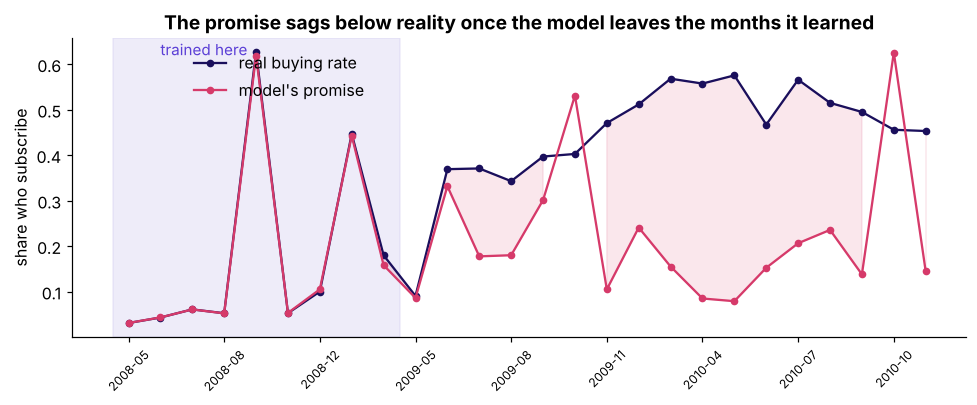

In [5]:
periods = sorted(bank["period"].unique())
p_all = stale.predict_proba(X)[:, 1]
by_month = pd.DataFrame({"period": bank["period"], "real": y, "promised": p_all}).groupby("period").agg(
    calls=("real", "size"), real=("real", "mean"), promised=("promised", "mean")).reindex(periods)

fig, ax = plt.subplots(figsize=(9, 3.8))
xs = np.arange(len(periods))
ax.axvspan(-0.5, list(periods).index(bank.loc[early[-1], "period"]) + 0.5, color=LILAC, alpha=0.35)
ax.plot(xs, by_month["real"], "-o", color=INK, ms=4, label="real buying rate")
ax.plot(xs, by_month["promised"], "-o", color=ROSE, ms=4, label="model's promise")
ax.fill_between(xs, by_month["promised"], by_month["real"], where=by_month["real"] > by_month["promised"], color=ROSE, alpha=0.12)
ax.text(1, 0.62, "trained here", color=VIOLET, fontsize=10)
ax.set_xticks(xs[::3]); ax.set_xticklabels(periods[::3], rotation=45, fontsize=8)
ax.set_ylabel("share who subscribe"); ax.legend(loc="upper left", bbox_to_anchor=(0.12, 1.0), frameon=False)
ax.set_title("The promise sags below reality once the model leaves the months it learned")
plt.tight_layout(); plt.show()

## What rule would have caught it, and in which month?

A monitoring rule has four parts: the number watched, the ceiling, the window, and the person who acts. The number: each month, the share of called customers who subscribed against the share the model promised them. The list is the 12 percent of each month's customers the model ranks highest, the same share as 1,000 calls in 8,238. The ceiling comes from Week 1's sample size: with about 100 calls a month and a promise near 30 in 100, luck alone moves the share by about `2 x sqrt(0.3 x 0.7 / 100) = 0.09`, nine points, so the ceiling sits at ten.

In [6]:
SHARE, CEILING = 1000 / 8238, 0.10
rows = []
for per in sorted(bank.loc[late, "period"].unique()):
    month = bank.loc[late][bank.loc[late, "period"] == per].index
    p, yy = stale.predict_proba(X.loc[month])[:, 1], y[month].to_numpy()
    k = max(1, round(len(month) * SHARE)); top = np.argsort(-p, kind="stable")[:k]
    rows.append({"month": per, "called": k, "promised": round(p[top].mean(), 3), "real": round(yy[top].mean(), 3)})
monitor = pd.DataFrame(rows)
monitor["gap"] = (monitor["real"] - monitor["promised"]).round(3)
monitor["over ceiling"] = monitor["gap"].abs() > CEILING
monitor["alarm"] = monitor["over ceiling"] & monitor["over ceiling"].shift(1, fill_value=False)
first_alarm = monitor.loc[monitor["alarm"], "month"].iloc[0]
print("first month the rule fires:", first_alarm)
monitor.head(8)

first month the rule fires: 2009-08


,month,called,promised,real,gap,over ceiling,alarm
0,2009-04,194,0.226,0.309,0.083,False,False
1,2009-05,703,0.136,0.142,0.006,False,False
2,2009-06,87,0.451,0.460,0.009,False,False
3,2009-07,22,0.324,0.545,0.221,True,False
4,2009-08,93,0.316,0.441,0.125,True,True
5,2009-09,32,0.446,0.469,0.023,False,False
6,2009-10,54,0.704,0.630,-0.074,False,False
7,2009-11,43,0.198,0.628,0.430,True,False


In [7]:
check("the real buying rate on the late rows is at least three times the early rate", y_late.mean() > 3 * y[early].mean())
check("the stale model's bill is above calling everyone", actual["bill_rs"] > everyone["bill_rs"])
check("the rule needs two months in a row before it fires", monitor["alarm"].sum() < monitor["over ceiling"].sum())

PASS  the real buying rate on the late rows is at least three times the early rate
PASS  the stale model's bill is above calling everyone
PASS  the rule needs two months in a row before it fires


## Which segment does today's model rank worst, and can we trust the reading?

Back on the random validation slice, the honest model is scored inside each job group. AUC inside a group asks: pick one buyer and one non-buyer from this group; how often does the buyer score higher? A group with few buyers gives a jumpy answer, so each reading carries a band from 200 resamples, the Week 1 sample-size lesson again.

In [8]:
chosen = logistic().fit(X.loc[train], y[train])
v = bank.loc[val, ["job", "contact"]].copy()
v["p"], v["yy"] = chosen.predict_proba(X.loc[val])[:, 1], y[val].to_numpy()
rng = np.random.default_rng(1)
def auc_band(t, n=200):
    a = [roc_auc_score(t.yy.values[s], t.p.values[s]) for s in (rng.integers(0, len(t), len(t)) for _ in range(n))
         if t.yy.values[s].min() != t.yy.values[s].max()]
    return np.percentile(a, [2.5, 97.5])
seg = []
for job, t in v.groupby("job"):
    lo, hi = auc_band(t)
    seg.append({"job": job, "customers": len(t), "buyers": int(t.yy.sum()),
                "AUC": round(roc_auc_score(t.yy, t.p), 3), "band low": round(lo, 2), "band high": round(hi, 2)})
seg = pd.DataFrame(seg).sort_values("AUC").reset_index(drop=True)
seg

,job,customers,buyers,AUC,band low,band high
0,entrepreneur,275,26,0.655,0.54,0.81
1,blue-collar,1834,122,0.707,0.65,0.76
2,management,589,68,0.757,0.68,0.83
3,unknown,66,6,0.758,0.57,0.94
4,student,183,58,0.759,0.69,0.83
5,services,808,60,0.774,0.70,0.84
6,self-employed,262,30,0.780,0.68,0.86
7,technician,1354,144,0.786,0.74,0.84
8,admin.,2114,286,0.800,0.77,0.83
9,housemaid,208,18,0.848,0.74,0.95


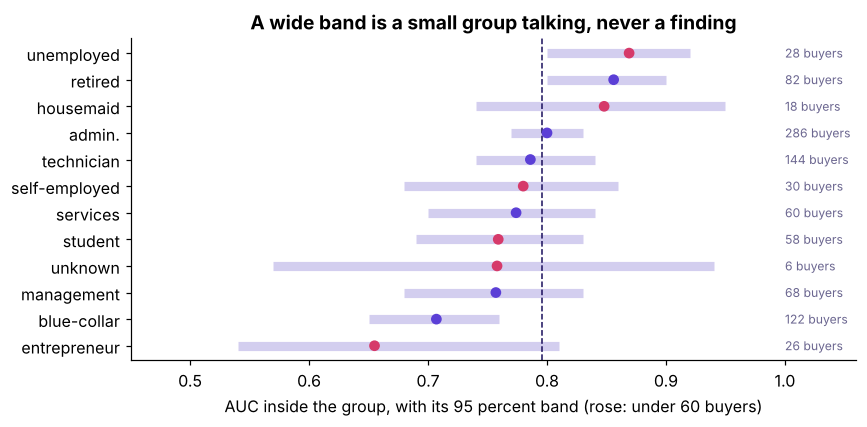

,customers,buyers,AUC
contact,,,
cellular,5255,779,0.779
telephone,2983,149,0.721


In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
colors = [ROSE if b < 60 else VIOLET for b in seg["buyers"]]
ax.errorbar(seg["AUC"], seg["job"], xerr=[seg["AUC"] - seg["band low"], seg["band high"] - seg["AUC"]],
            fmt="none", ecolor=LILAC, elinewidth=6, alpha=0.9)
ax.scatter(seg["AUC"], seg["job"], color=colors, zorder=3)
for _, r in seg.iterrows():
    ax.text(1.0, r["job"], f"{r['buyers']} buyers", va="center", fontsize=8, color=MUTED)
ax.axvline(roc_auc_score(v.yy, v.p), color=INK, ls="--", lw=1)
ax.set_xlim(0.45, 1.06); ax.set_xlabel("AUC inside the group, with its 95 percent band (rose: under 60 buyers)")
ax.set_title("A wide band is a small group talking, never a finding")
plt.tight_layout(); plt.show()
contact = pd.DataFrame([{"contact": c, "customers": len(t), "buyers": int(t.yy.sum()),
                         "AUC": round(roc_auc_score(t.yy, t.p), 3)} for c, t in v.groupby("contact")]).set_index("contact")
contact

In [10]:
big = seg[seg["buyers"] >= 100]
check("the lowest-AUC job rests on fewer buyers than the weakest large group", seg.loc[0, "buyers"] < big.iloc[0]["buyers"])
check("telephone contacts are ranked worse than mobile contacts", contact.loc["telephone", "AUC"] < contact.loc["cellular", "AUC"])

PASS  the lowest-AUC job rests on fewer buyers than the weakest large group
PASS  telephone contacts are ranked worse than mobile contacts


## What does a stale model cost a real company?

Zillow Offers bought homes on a price forecast and needed to know the price three to six months out. In its 8-K of 2 November 2021 Zillow recorded a "$304.4 million write-down of inventory", expected "approximately $240 million to $265 million" more, and a wind-down that would cut about 25 percent of its workforce; the shareholder letter says "We have been unable to accurately forecast future home prices at different times in both directions". Source: https://www.sec.gov/Archives/edgar/data/1617640/000161764021000085/z-20211102.htm (verified 28 October 2026). The bank's model is small and its bill is in thousands of rupees; the mechanism is the same one: the world moved and the forecast kept its old promise.

In [11]:
weakest = big.iloc[0]
print(f"CAVEAT.  Stale when the share of called customers who subscribe sits more than {CEILING * 100:.0f} points away from the")
print(f"         promised share two months running; on this file the rule would have fired in {first_alarm}.")
print(f"         Weakest large group: {weakest['job']} (AUC {weakest['AUC']}, {weakest['buyers']} buyers); telephone contacts "
      f"{contact.loc['telephone', 'AUC']} against {contact.loc['cellular', 'AUC']} on mobiles.")

CAVEAT.  Stale when the share of called customers who subscribe sits more than 10 points away from the
         promised share two months running; on this file the rule would have fired in 2009-08.
         Weakest large group: blue-collar (AUC 0.707, 122 buyers); telephone contacts 0.721 against 0.779 on mobiles.


## What did this chapter establish, and what does the next one add?

| Question | Answer from this run |
|---|---|
| What moves first when the world changes? | The real buying rate, from about 6 to about 25 in 100, while the promise stays near 16 |
| Does AUC show it? | It falls from 0.80 to 0.66 and never mentions the promise the bill rests on |
| What did staleness cost? | At 0.032 the stale model's bill is about Rs 89,000 above calling everyone |
| The rule | Promise against reality among called customers, ceiling ten points, two months running, Kavya acts |
| Weakest segment | The weakest group with 100 or more buyers, with its band beside it; small groups read as noise |

The next notebook moves the same pipeline to Rohan's lending book and opens the envelope.